In [2]:
import geopandas as gpd

print("GeoPandas installed successfully!")
print("Version:", gpd.__version__)

GeoPandas installed successfully!
Version: 1.2.0


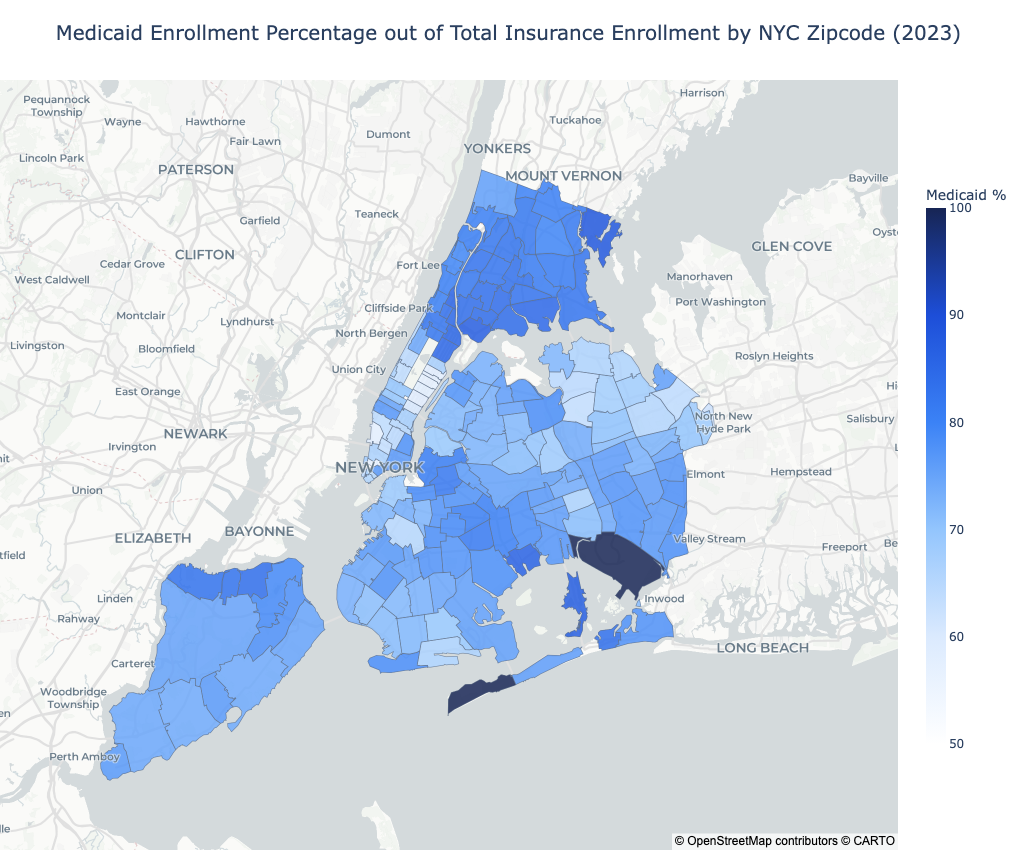

ZIP codes mapped: 181
Minimum Medicaid enrollment percentage: 57.57
Maximum Medicaid enrollment percentage: 100.0


,Zip_Code,Total_Enrollments,Medicaid Count,Medicaid Percentage
221,11697,146.0,146.0,100.000000
210,11430,86.0,86.0,100.000000
105,10464,692.0,609.0,88.005780
95,10454,20463.0,17809.0,87.030250
219,11693,3448.0,2999.0,86.977958
165,11239,4900.0,4228.0,86.285714
36,10039,10932.0,9411.0,86.086718
32,10035,13117.0,11218.0,85.522604
34,10037,6333.0,5400.0,85.267646
26,10029,30500.0,25960.0,85.114754


In [3]:

import pandas as pd
import numpy as np
import json
import plotly.express as px

# LOADING NY STATE ENROLLMENT DATA

program_zip_df = pd.read_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    dtype={"Zip_Code": "string"}
)

with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson",
    "r"
) as f:
    zip_geojson = json.load(f)

program_zip_df.columns = program_zip_df.columns.str.strip()

# CLEAN ZIP CODES

program_zip_df["Zip_Code"] = (
    program_zip_df["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# STANDARDIZE GEOJSON ZIP CODES

for feature in zip_geojson["features"]:
    feature["properties"]["Zip_Code"] = (
        str(feature["properties"]["postalCode"])
        .strip()
        .zfill(5)
    )

# DEFINE INSURANCE PROGRAMS

program_types = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_columns = [
    f"{program} Count"
    for program in program_types
]

# CLEAN ENROLLMENT COUNTS

for col in count_columns:
    program_zip_df[col] = pd.to_numeric(
        program_zip_df[col]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# CALCULATE TOTAL ENROLLMENTS

program_zip_df["Total_Enrollments"] = (
    program_zip_df[count_columns].sum(axis=1)
)

# CALCULATE ENROLLMENT PERCENTAGES

for program in program_types:

    program_zip_df[f"{program} Percentage"] = (
        program_zip_df[f"{program} Count"]
        / program_zip_df["Total_Enrollments"].replace(0, np.nan)
        * 100
    )

# FILTER TO ZIP CODES IN GEOJSON

mapped_zips = {
    feature["properties"]["Zip_Code"]
    for feature in zip_geojson["features"]
}

map_df = program_zip_df[
    program_zip_df["Zip_Code"].isin(mapped_zips)
].copy()

# Exclude ZIP codes with zero enrollments
map_df = map_df[
    map_df["Total_Enrollments"] > 0
].copy()

# DEFININHG CUSTOM COLOR GRADIENT

# 50% = white
# 100% = darkest blue

medicaid_colors = [
    [0.00, "#FFFFFF"],  # 50%
    [0.20, "#DBEAFE"],  # 60%
    [0.40, "#93C5FD"],  # 70%
    [0.60, "#3B82F6"],  # 80%
    [0.80, "#1D4ED8"],  # 90%
    [1.00, "#172554"]   # 100%
]

#  DEFINE HOVER DATA 
hover_columns = [
    "Zip_Code",
    "Total_Enrollments",

    "Medicaid Count",
    "Medicaid Percentage",

    "CHP Count",
    "CHP Percentage",

    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",

    "QHP Full Pay Count",
    "QHP Full Pay Percentage",

    "Essential Plan Count",
    "Essential Plan Percentage"
]

# CREATE CHOROPLETH MAP

fig = px.choropleth_map(
    map_df,

    geojson=zip_geojson,

    locations="Zip_Code",

    featureidkey="properties.Zip_Code",

    color="Medicaid Percentage",

    color_continuous_scale=medicaid_colors,

    range_color=(50, 100),

    custom_data=hover_columns,

    map_style="carto-positron",

    center={
        "lat": 40.7128,
        "lon": -73.94
    },

    zoom=9.6,

    opacity=0.85,

    title=(
        "Medicaid Enrollment Percentage "
        "by NYC ZIP Code"
    ),

    height=850
)

# CUSTOMIZE HOVER INFORMATION

fig.update_traces(
    hovertemplate=(
        "<b>ZIP Code: %{customdata[0]}</b><br>"
        "<br>"

        "<b>Total Insurance Enrollments:</b> "
        "%{customdata[1]:,.0f}<br>"

        "<br><b>MEDICAID</b><br>"
        "Enrollments: %{customdata[2]:,.0f}<br>"
        "Percentage: %{customdata[3]:.2f}%<br>"

        "<br><b>CHP</b><br>"
        "Enrollments: %{customdata[4]:,.0f}<br>"
        "Percentage: %{customdata[5]:.2f}%<br>"

        "<br><b>QHP APTC w/o CSR</b><br>"
        "Enrollments: %{customdata[6]:,.0f}<br>"
        "Percentage: %{customdata[7]:.2f}%<br>"

        "<br><b>QHP FULL PAY</b><br>"
        "Enrollments: %{customdata[8]:,.0f}<br>"
        "Percentage: %{customdata[9]:.2f}%<br>"

        "<br><b>ESSENTIAL PLAN</b><br>"
        "Enrollments: %{customdata[10]:,.0f}<br>"
        "Percentage: %{customdata[11]:.2f}%"

        "<extra></extra>"
    ),

    marker_line_width=0.6,
    marker_line_color="#64748B"
)

# CUSTOMIZE COLORBAR

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Medicaid %",
        ticksuffix="%",
        tickvals=[
            50, 60, 70, 80, 90, 100
        ],
        len=0.75,
        thickness=20
    )
)

#   Map Features -- need to play with before layering step...

fig.update_layout(
    title=dict(
        text=(
            "Medicaid Enrollment Percentage "
            "out of Total Insurance Enrollment "
            "by NYC Zipcode (2023)"
        ),
        x=0.5,
        font=dict(size=20)
    ),

    margin=dict(
        l=0,
        r=0,
        t=80,
        b=0
    ),

    height=850,

    paper_bgcolor="white"
)

#  DISPLAY MAP

fig.show()

# SAVINGH INTERACTIVE HTML MAP

fig.write_html(
    "NYC_Medicaid_Enrollment_Map.html"
)

#  CHECK RESULTS

print(
    "ZIP codes mapped:",
    map_df["Zip_Code"].nunique()
)

print(
    "Minimum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].min(), 2)
)

print(
    "Maximum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].max(), 2)
)

display(
    map_df[
        [
            "Zip_Code",
            "Total_Enrollments",
            "Medicaid Count",
            "Medicaid Percentage"
        ]
    ].sort_values(
        "Medicaid Percentage",
        ascending=False
    ).head(15)
)
